# Walkthrough: grouping OCR text into recipes

OCR on a scanned page gives you text boxes, but not which boxes belong to the same recipe. This
notebook runs [`recipe_continuity.py`](recipe_continuity.py) one step at a time and shows what each
step produces, so you can see how layout, strands decider and a few lines of code split the work:

1. **The page:** 16 OCR boxes from an invented Arabic cookbook, read right to left.
2. **Layout proposes** which box could come next after each box.
3. **One question, in full:** the exact request and answer for one pair.
4. **Every question:** the score for each of the 14 candidate pairs.
5. **Code settles** the links into recipes, and we compare them with the hand labels.
6. **`noul` vs `choice`:** the same pairs asked as a "this block, or none?" `choice`.
7. **The criteria wording** and how much it changes the result.

The outputs below are saved, so you can read the notebook without running it. To run it yourself,
start a server first (see the [README](README.md)), then run the cells in order. Each takes a
second or two.

In [1]:
import json
import textwrap

import draw  # SVG pictures for this notebook (draw.py, next to this file)
import recipe_continuity as rc  # the example script; we call its functions step by step
from IPython.display import Markdown, display


def show(svg: str) -> None:
    """Display an SVG picture exactly as draw.py wrote it."""
    display({"image/svg+xml": svg}, raw=True)


page = json.loads(open("arabic_cookbook.json", encoding="utf-8").read())
boxes = {b["id"]: b for b in page["boxes"]}
print(f"{len(boxes)} boxes, read {page['page']['direction']}; server at {rc.URL}")

16 boxes, read rtl; server at http://127.0.0.1:8099


## 1. The page

The page has three columns, read right to left, and a page header across the top. Each box has a
hand label (`recipe`) that the script uses only to score its output. The colours below are those
labels; the header (grey) belongs to no recipe. The English glosses are for readers who don't read
Arabic; the model only sees the Arabic text.

The page has four traps:

- **k03 → k04:** the shakshuka method is cut off mid-sentence at the foot of the right column and
  finishes at the top of the middle one ("…into each hollow is broken" / "one egg…").
- **k10 → k11:** the spinach pies paragraph is split mid-sentence inside a column.
- **k04 → k05:** a second egg dish, the herb omelette, starts right under the end of the shakshuka.
- **k13, k14, k15:** three short tips stacked one under another, each its own item.

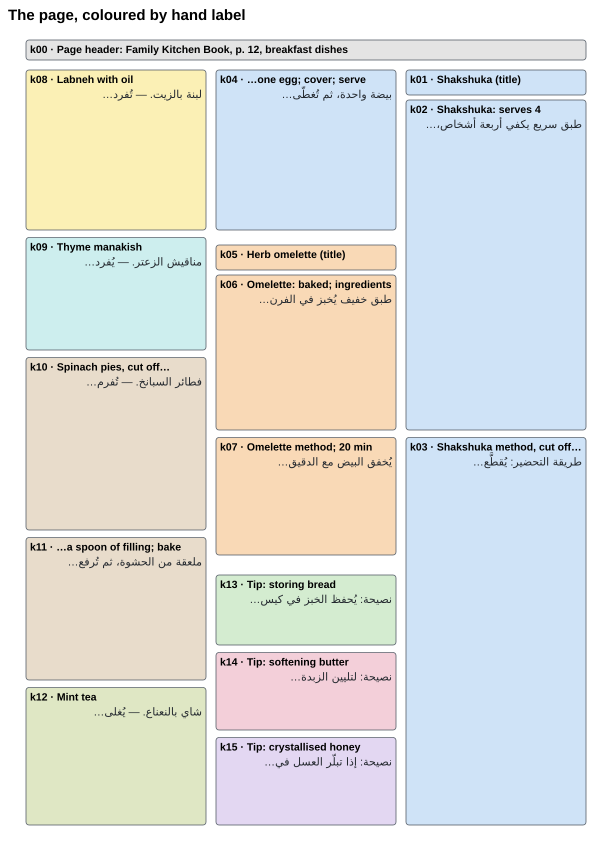

| recipe (label) | boxes | English |
|---|---|---|
| (header) | k00 | Page header: Family Kitchen Book, p. 12, breakfast dishes |
| shakshuka | k01 k02 k03 k04 | Shakshuka (title) |
| herb_omelette | k05 k06 k07 | Herb omelette (title) |
| tip_bread | k13 | Tip: storing bread |
| tip_butter | k14 | Tip: softening butter |
| tip_honey | k15 | Tip: crystallised honey |
| labneh | k08 | Labneh with oil |
| manakish | k09 | Thyme manakish |
| spinach_pies | k10 k11 | Spinach pies, cut off… |
| mint_tea | k12 | Mint tea |

In [2]:
ENGLISH = {  # short glosses, only for the pictures and tables in this notebook
    "k00": "Page header: Family Kitchen Book, p. 12, breakfast dishes",
    "k01": "Shakshuka (title)",
    "k02": "Shakshuka: serves 4",
    "k03": "Shakshuka method, cut off…",
    "k04": "…one egg; cover; serve",
    "k05": "Herb omelette (title)",
    "k06": "Omelette: baked; ingredients",
    "k07": "Omelette method; 20 min",
    "k08": "Labneh with oil",
    "k09": "Thyme manakish",
    "k10": "Spinach pies, cut off…",
    "k11": "…a spoon of filling; bake",
    "k12": "Mint tea",
    "k13": "Tip: storing bread",
    "k14": "Tip: softening butter",
    "k15": "Tip: crystallised honey",
}

labels: dict[str, list[str]] = {}  # recipe label -> its box ids, in reading order
for b in page["boxes"]:
    labels.setdefault(b["recipe"] or "(header)", []).append(b["id"])
truth = [ids for name, ids in labels.items() if name != "(header)"]
fill = draw.colours_for(list(labels.values()), skip=frozenset({"k00"}))
show(draw.page_svg(page, fill, gloss=ENGLISH, title="The page, coloured by hand label"))

rows = ["| recipe (label) | boxes | English |", "|---|---|---|"]
rows += [f"| {name} | {' '.join(ids)} | {ENGLISH[ids[0]]} |" for name, ids in labels.items()]
display(Markdown("\n".join(rows)))

## 2. Step 1: layout proposes candidates

Asking the model about every pair of boxes would be 240 questions. Layout already says which box
*could* come next: the box directly below in the same column, or, at the foot of a column, the top
of the nearest column on the reading side. `run()` first sets aside boxes that lie over two columns
(the page header), then calls `candidates()`. The dashed arrows are its proposals.

set aside as a header: ['k00']
14 candidate pairs; most candidates for one box: 1


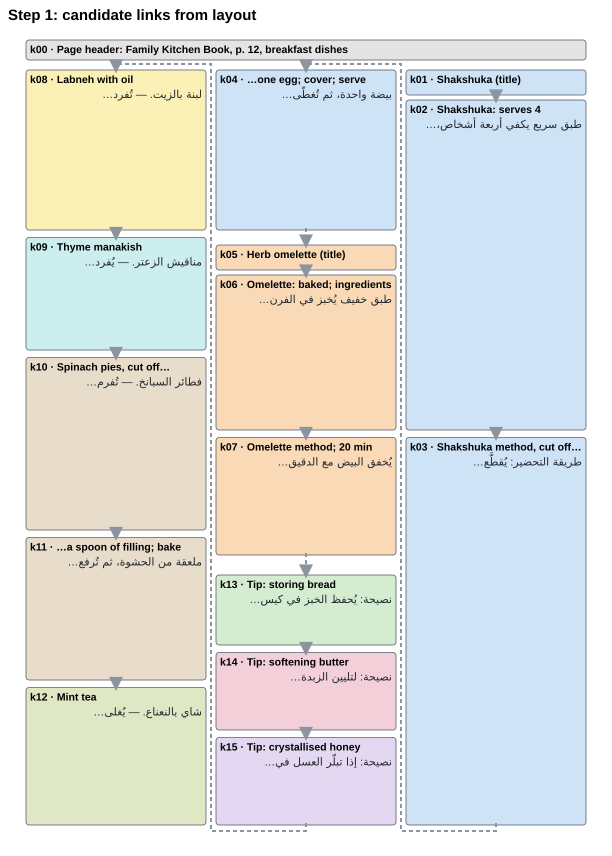

In [3]:
body = [b for b in page["boxes"] if not rc.spans_columns(b, page["boxes"])]
print("set aside as a header:", [b["id"] for b in page["boxes"] if b not in body])

by_id = {b["id"]: b for b in body}
cands = rc.candidates(body, rtl=page["page"]["direction"] == "rtl")
pairs = [(a, b) for a, bs in cands.items() for b in bs]
print(f"{len(pairs)} candidate pairs; most candidates for one box: {max(map(len, cands.values()))}")

proposals = [(a, b, draw.DASHED, "") for a, b in pairs]
show(draw.page_svg(page, fill, proposals, ENGLISH, "Step 1: candidate links from layout"))

Every box here has exactly one candidate (the last box, k12, has none), so the page needs 14
questions. Layout alone can't tell which proposals are real: linking all 14 would chain almost the
whole page into one "recipe". That judgement needs someone, or something, to read the text.

## 3. Step 2: one question, in full

Take the hardest pair, k03 → k04, where the recipe continues at the top of the next column. The
script sends a `noul` question: a yes/no question that returns P(yes). The *state* is the text the
model reads: the end of box A, one line of layout context, and the start of box B. The two
*criteria* say what "yes" (`true`) and "no" (`false`) mean on this page. Here is the exact
request and the answer.

In [4]:
def recording(log: list):
    """Wrap rc.ask_server so every request and answer is kept in `log`."""

    def ask(state, questions):
        answers = rc.ask_server(state, questions)
        log.append({"state": state, "questions": questions, "answers": answers})
        return answers

    return ask


log: list = []
p = rc.ask_noul(by_id, "k03", "k04", recording(log))
print("STATE (what the model reads):\n" + log[0]["state"] + "\n")
print("QUESTIONS:\n" + json.dumps(log[0]["questions"], ensure_ascii=False, indent=1) + "\n")
print("ANSWER:\n" + json.dumps(log[0]["answers"]))
print(f"\nP(B continues A's recipe) = {p:.2f}; the script accepts a link at {rc.ACCEPT} or more.")

STATE (what the model reads):
Text blocks OCR'd from a scanned cookbook page. The OCR text may contain errors.
Block A ends: "طريقة التحضير: يُقطَّع البصل والفلفل قطعاً صغيرة ويُقلّبان في الزيت حتى يذبلا. يُضاف الثوم والكمون، ثم الطماطم المفرومة، ويُترك المزيج على نار متوسطة نحو عشر دقائق حتى يتماسك. تُعمل في الصلصة ست حفر صغيرة بظهر الملعقة، ويُكسر في كل حفرة"
Block B is at the top of the next column. It starts: "بيضة واحدة، ثم تُغطّى القدر وتُترك على نار هادئة حتى ينضج بياض البيض ويبقى الصفار طرياً. تُقدّم الشكشوكة في قدرها مباشرة."

QUESTIONS:
{
 "same": {
  "type": "noul",
  "instructions": "Do Block A and Block B belong to the same recipe?",
  "criteria": {
   "true": "B carries on A's recipe, or A is the title of B's recipe. A sentence cut off at the end of A and finished at the start of B is strong evidence.",
   "false": "B starts a different recipe or a tip: it opens with a dish name followed by a full stop or dash, or with 'نصيحة'. This holds even when B is about an ingredien

A yes, but a narrow one. The instructions and criteria are in English and the block text stays in
Arabic, with no translation step.

## 4. Every question

Now the same question for all 14 candidate pairs. Blue bars are pairs that truly belong to the same
recipe (by the hand labels), orange bars are pairs that don't. A good answer puts blue bars right of
the dashed 0.5 line and orange bars left of it.

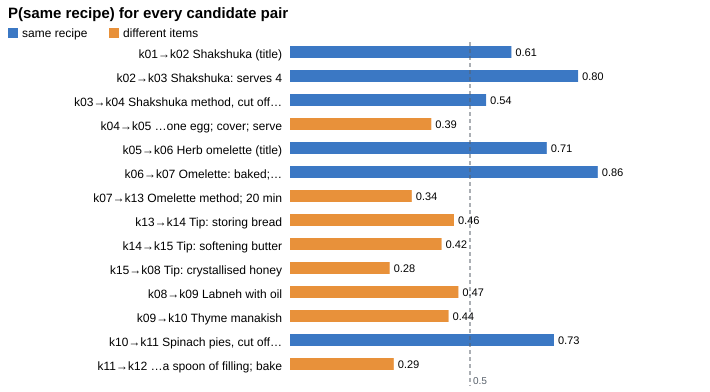

| pair | truly same? | P(same) | link? | right? |
|---|---|---|---|---|
| k01 → k02 | yes | 0.61 | link | ✓ |
| k02 → k03 | yes | 0.80 | link | ✓ |
| k03 → k04 | yes | 0.54 | link | ✓ |
| k04 → k05 | no | 0.39 | - | ✓ |
| k05 → k06 | yes | 0.71 | link | ✓ |
| k06 → k07 | yes | 0.86 | link | ✓ |
| k07 → k13 | no | 0.34 | - | ✓ |
| k13 → k14 | no | 0.46 | - | ✓ |
| k14 → k15 | no | 0.42 | - | ✓ |
| k15 → k08 | no | 0.28 | - | ✓ |
| k08 → k09 | no | 0.47 | - | ✓ |
| k09 → k10 | no | 0.44 | - | ✓ |
| k10 → k11 | yes | 0.73 | link | ✓ |
| k11 → k12 | no | 0.29 | - | ✓ |

lowest true pair: 0.54, highest different pair: 0.47


In [5]:
BLUE, ORANGE = "#3b78c4", "#e8913a"
recipe_of = {b["id"]: b["recipe"] for b in page["boxes"]}
same = {(a, b): recipe_of[a] == recipe_of[b] for a, b in pairs}  # the right answer, from labels
noul = {(a, b): rc.ask_noul(by_id, a, b, rc.ask_server) for a, b in pairs}


def name(a: str, b: str) -> str:
    """A short row label: the pair and the start of box A's gloss."""
    return f"{a}→{b}  " + textwrap.shorten(ENGLISH[a], 26, placeholder="…")


bars = [(name(a, b), [(noul[a, b], BLUE if same[a, b] else ORANGE)]) for a, b in pairs]
legend = [("same recipe", BLUE), ("different items", ORANGE)]
show(draw.bars_svg(bars, legend, rc.ACCEPT, "P(same recipe) for every candidate pair"))

rows = ["| pair | truly same? | P(same) | link? | right? |", "|---|---|---|---|---|"]
for a, b in pairs:
    link = noul[a, b] >= rc.ACCEPT
    ok = "✓" if link == same[a, b] else "✗"
    yes_no = "yes" if same[a, b] else "no"
    rows.append(f"| {a} → {b} | {yes_no} | {noul[a, b]:.2f} | {'link' if link else '-'} | {ok} |")
display(Markdown("\n".join(rows)))
print(
    f"lowest true pair: {min(p for k, p in noul.items() if same[k]):.2f}, "
    f"highest different pair: {max(p for k, p in noul.items() if not same[k]):.2f}"
)

All 14 answers fall on the right side of 0.5, but the margins are thin: the column jump scores
0.54 and labneh → manakish, two different recipes, scores 0.47. The docs' routing convention says
to confirm answers between 0.5 and 0.9 before acting on them, so treat these links as proposals.

## 5. Step 3: code settles the links

`settle()` accepts links strongest first, gives each box at most one next and one previous box,
skips any link that would close a loop, and follows the links into chains. `run()` does steps 1 to
3 in one call. In the pictures below, each fill colour is one group the script built, green
arrows are links that match the labels, red arrows are links that don't, and a red outline marks
a group that doesn't match a labelled recipe.

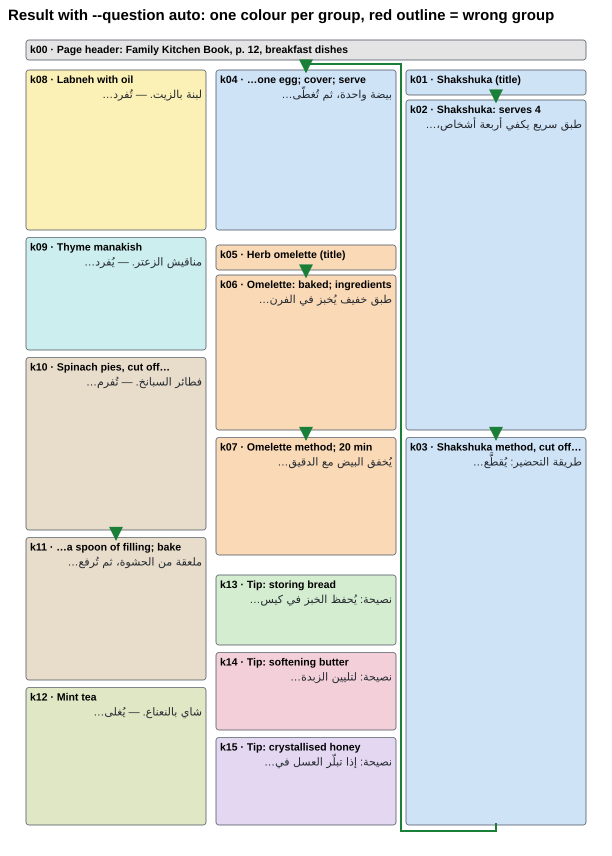

9/9 recipes match the labels (auto questions)
groups: [['k01', 'k02', 'k03', 'k04'], ['k05', 'k06', 'k07'], ['k13'], ['k14'], ['k15'], ['k08'], ['k09'], ['k10', 'k11'], ['k12'], ['k00']]


In [6]:
def show_result(mode: str) -> list[list[str]]:
    """Run the whole pipeline in one mode, draw the groups, and print the score."""
    groups = rc.run(page, mode)
    true_links = {(ids[i], ids[i + 1]) for ids in truth for i in range(len(ids) - 1)}
    arrows = [
        (g[i], g[i + 1], GREEN_OR_RED[(g[i], g[i + 1]) in true_links], "")
        for g in groups
        for i in range(len(g) - 1)
    ]
    wrong = {i for g in groups if set(g) not in map(set, truth) and g != ["k00"] for i in g}
    title = f"Result with --question {mode}: one colour per group, red outline = wrong group"
    show(
        draw.page_svg(
            page,
            draw.colours_for(groups, frozenset({"k00"})),
            arrows,
            ENGLISH,
            title,
            flagged=wrong,
        )
    )
    correct = sum(set(g) in map(set, truth) for g in groups)
    print(f"{correct}/{len(truth)} recipes match the labels ({mode} questions)")
    return groups


GREEN_OR_RED = {True: draw.GREEN, False: draw.RED}
groups = show_result("auto")
print("groups:", groups)

## 6. `noul` vs `choice`

A `choice` picks one of several options, and returns one probability per option that adds up to 1.
With `--question choice` the script asks, for each box, "which block continues this recipe?" with
the candidate and a `none` option, and keeps the candidate unless `none` wins. That is a choice
that also decides whether the link exists.

Below, for each pair, the `noul`'s P(same) next to the `choice`'s share for the candidate.

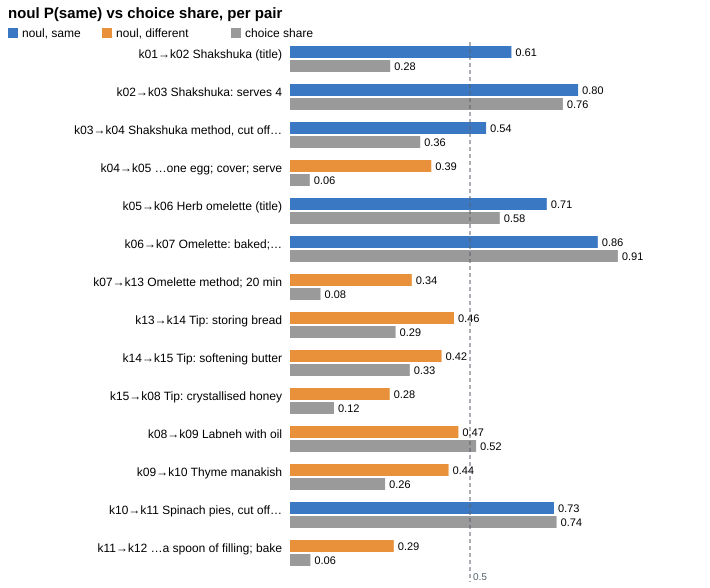

pairs the choice gets wrong: ['k01→k02 (Shakshuka (title) → Shakshuka: serves 4)', 'k03→k04 (Shakshuka method, cut off… → …one egg; cover; serve)', 'k08→k09 (Labneh with oil → Thyme manakish)']


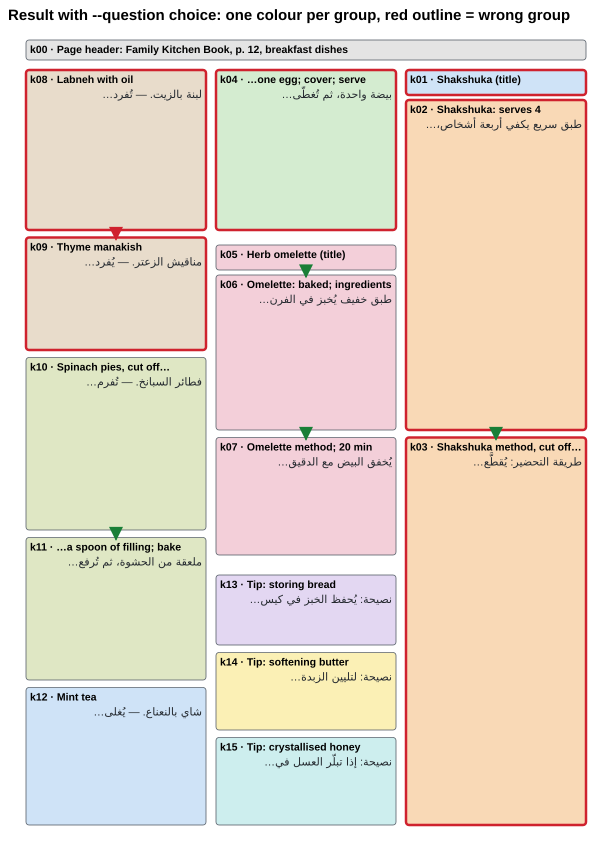

6/9 recipes match the labels (choice questions)


In [7]:
share = {(a, b): rc.ask_choice(by_id, a, [b], rc.ask_server, with_none=True)[b] for a, b in pairs}

bars = [
    (name(a, b), [(noul[a, b], BLUE if same[a, b] else ORANGE), (share[a, b], "#9a9a9a")])
    for a, b in pairs
]
legend = [("noul, same", BLUE), ("noul, different", ORANGE), ("choice share", "#9a9a9a")]
show(draw.bars_svg(bars, legend, 0.5, "noul P(same) vs choice share, per pair"))

wrong = [(a, b) for a, b in pairs if (share[a, b] > 0.5) != same[a, b]]
print("pairs the choice gets wrong:", [f"{a}→{b} ({ENGLISH[a]} → {ENGLISH[b]})" for a, b in wrong])
groups_choice = show_result("choice")

The `choice` misses the title → text link of the shakshuka and the column jump, and joins labneh and
manakish, two separate recipes: 6 of 9. In our reading, a single candidate against an abstract
`none` is an awkward question for a choice. That is the rule the example follows: use a `noul` to
decide whether a link exists, and a `choice` to rank several candidates. With several candidates,
the default mode asks a `choice` without `none` to rank them, then a `noul` about the top one.

## 7. The criteria wording matters as much

The `false` criterion names what starts a new item on this page: a dish name followed by a full stop
or a dash, or the word نصيحة (tip). Here is the same run with a generic `false` criterion instead.

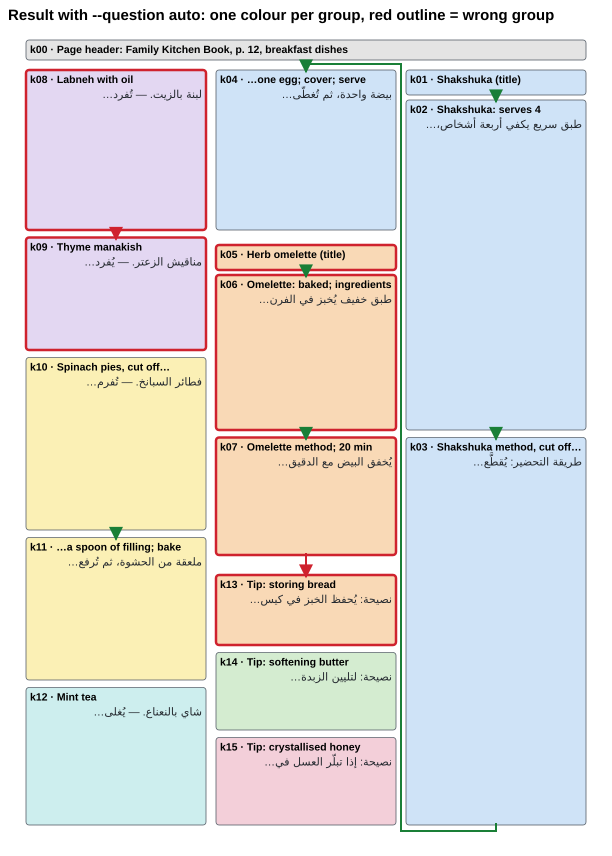

5/9 recipes match the labels (auto questions)


| pair | truly same? | sharp criteria | generic criteria |
|---|---|---|---|
| k01 → k02 | yes | 0.61 ✓ | 0.72 ✓ |
| k02 → k03 | yes | 0.80 ✓ | 0.91 ✓ |
| k03 → k04 | yes | 0.54 ✓ | 0.54 ✓ |
| k04 → k05 | no | 0.39 ✓ | 0.22 ✓ |
| k05 → k06 | yes | 0.71 ✓ | 0.82 ✓ |
| k06 → k07 | yes | 0.86 ✓ | 0.94 ✓ |
| k07 → k13 | no | 0.34 ✓ | 0.52 ✗ |
| k13 → k14 | no | 0.46 ✓ | 0.43 ✓ |
| k14 → k15 | no | 0.42 ✓ | 0.44 ✓ |
| k15 → k08 | no | 0.28 ✓ | 0.23 ✓ |
| k08 → k09 | no | 0.47 ✓ | 0.57 ✗ |
| k09 → k10 | no | 0.44 ✓ | 0.32 ✓ |
| k10 → k11 | yes | 0.73 ✓ | 0.90 ✓ |
| k11 → k12 | no | 0.29 ✓ | 0.13 ✓ |

In [8]:
sharp = rc.SAME
rc.SAME = dict(sharp, false="B starts a different recipe, a new title, or a separate tip.")
try:
    generic = {(a, b): rc.ask_noul(by_id, a, b, rc.ask_server) for a, b in pairs}
    groups_generic = show_result("auto")
finally:
    rc.SAME = sharp  # put the page's own criteria back


def mark(p: float, right: bool) -> str:
    """A score with ✓ if it lands on the correct side of ACCEPT, ✗ if not."""
    return f"{p:.2f} {'✓' if (p >= rc.ACCEPT) == right else '✗'}"


rows = ["| pair | truly same? | sharp criteria | generic criteria |", "|---|---|---|---|"]
for a, b in pairs:
    yes_no = "yes" if same[a, b] else "no"
    sharp_p, generic_p = mark(noul[a, b], same[a, b]), mark(generic[a, b], same[a, b])
    rows.append(f"| {a} → {b} | {yes_no} | {sharp_p} | {generic_p} |")
display(Markdown("\n".join(rows)))

With the generic wording the `noul` links the omelette to the bread tip and labneh to manakish, and
rebuilds only 5 of 9, fewer than the `choice`. So the `noul` wins on this page once its criteria
describe the page.

## What to take away

- Let layout propose and code settle; ask the model only the narrow question that needs reading.
- Use a `noul` to decide whether a link exists, and a `choice` to rank several candidates.
- Write criteria that name your documents' evidence, and check them on labelled pages you didn't
  tune them on: this is one synthetic page, tuned by hand.
- Every accepted link here scores between 0.5 and 0.9, so confirm the links before acting on them.